# 08 · Writer-independent evaluation

This notebook evaluates how well the CNN generalizes to handwriting from writers excluded from training. It reserves complete writers from the supplied training split for validation, selects hyperparameters using validation accuracy and loss, and evaluates the supplied test split once at the end.

The comparison graphs show validation accuracy and loss for every candidate. Accuracies within 0.05 percentage points of the best value are treated as effectively tied; from that group, the candidate with the lowest validation loss is selected. This avoids choosing a setting based on a tiny accuracy difference alone.


In [1]:
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit

from src.data import load_emnist
from src.preprocessing import preprocess_images
from src.writer_evaluation import (
    train_candidate,
    plot_comparison,
    select_by_accuracy_and_loss,
    candidate_summary,
)


I0000 00:00:1790191435.644487   71819 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790191435.888892   71819 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1790191437.229778   71819 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Prepare the data

All examples belonging to one writer are assigned to either model fitting or validation. This prevents the same writer's handwriting from appearing in both sets. The official test data is loaded here, but it is not used during model selection.


In [2]:
X_train_all, y_train_all, writers_train, X_test_raw, y_test, writers_test = load_emnist()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
fit_idx, val_idx = next(
    splitter.split(X_train_all, y_train_all, groups=writers_train)
)
fit_writers = set(writers_train[fit_idx])
val_writers = set(writers_train[val_idx])
assert fit_writers.isdisjoint(val_writers)

X_fit = preprocess_images(X_train_all[fit_idx])
y_fit = y_train_all[fit_idx]
X_val = preprocess_images(X_train_all[val_idx])
y_val = y_train_all[val_idx]
X_test = preprocess_images(X_test_raw)

print(f"Fit set:        {len(fit_idx):,} images, {len(fit_writers):,} writers")
print(f"Validation set: {len(val_idx):,} images, {len(val_writers):,} writers")
print(f"Test set:       {len(y_test):,} images")
print("Writer overlap between fit and validation:", len(fit_writers & val_writers))


Fit set:        203,752 images, 3,042 writers
Validation set: 36,248 images, 537 writers
Test set:       40,000 images
Writer overlap between fit and validation: 0


### Check the split

The writer counts below should show no overlap. The plot shows how many images were assigned to each partition; the image counts can differ because each writer contributed a different number of examples.


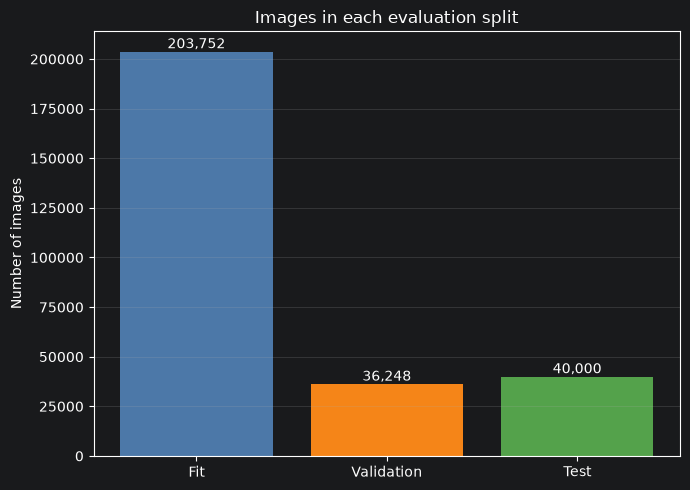

In [3]:
split_names = ["Fit", "Validation", "Test"]
image_counts = [len(y_fit), len(y_val), len(y_test)]
plt.figure(figsize=(7, 5))
bars = plt.bar(split_names, image_counts, color=["#4C78A8", "#F58518", "#54A24B"])
plt.ylabel("Number of images")
plt.title("Images in each evaluation split")
plt.grid(axis="y", alpha=0.25)
for bar, count in zip(bars, image_counts):
    plt.text(bar.get_x() + bar.get_width()/2, count, f"{count:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

assert len(fit_writers & val_writers) == 0


## Set up reusable training and comparison helpers

Each candidate uses the same CNN, data partitions, epoch limit, and early-stopping rule. The selection rule first finds candidates within 0.05 percentage points of the best validation accuracy, then chooses the one with the lowest validation loss. The graphs outline that selected candidate so the accuracy and loss trade-off is visible.

Candidate training, comparison plotting, selection, and result-summary functions are imported from `src/writer_evaluation.py`. The cells below keep the experiment choices and validation-based selection visible here.


## Compare learning rates

Dropout is held at 0.5 and batch size at 128. Candidates within 0.05 percentage points of the best validation accuracy are treated as tied; among them, the lower validation loss decides the selection.



Learning rate: 0.0001


W0000 00:00:1790191440.498842   71819 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Epoch 1/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.8876 - loss: 0.3863 - val_accuracy: 0.9745 - val_loss: 0.0872
Epoch 2/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9656 - loss: 0.1195 - val_accuracy: 0.9830 - val_loss: 0.0559
Epoch 3/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9748 - loss: 0.0884 - val_accuracy: 0.9865 - val_loss: 0.0450
Epoch 4/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9789 - loss: 0.0735 - val_accuracy: 0.9889 - val_loss: 0.0376
Epoch 5/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9822 - loss: 0.0622 - val_accuracy: 0.9897 - val_loss: 0.0354
Epoch 6/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9839 - loss: 0.0564 - val_accuracy: 0.9905 - val_loss: 0.0321
Epoch 7/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9848 - loss: 0.0522 - val_accuracy: 0.9914 - val_loss: 0.0303
Epoch 8/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9859 -

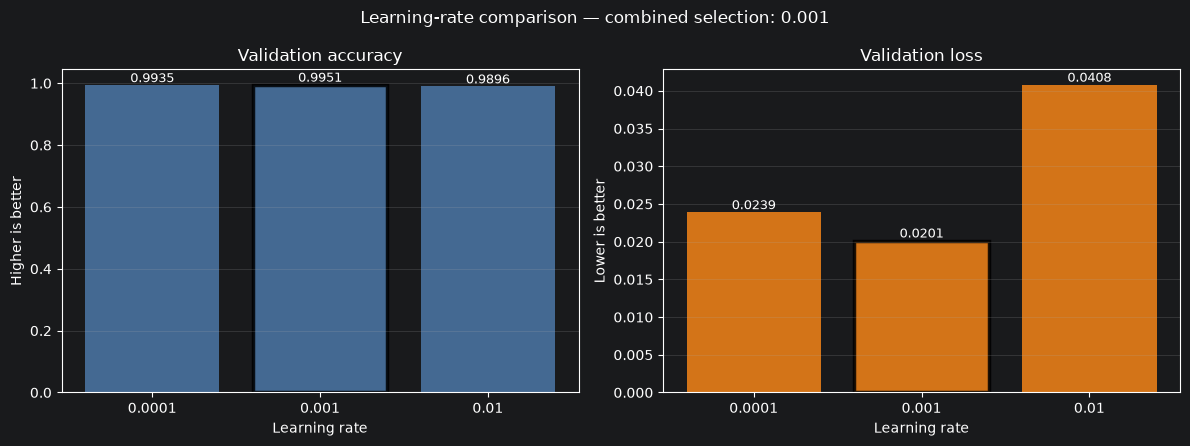

In [4]:
learning_rates = [0.0001, 0.001, 0.01]
lr_results = {}
for lr in learning_rates:
    print(f"\nLearning rate: {lr}")
    lr_results[lr] = train_candidate(
        X_fit, y_fit, X_val, y_val,
        learning_rate=lr, dropout_rate=0.5, batch_size=128,
    )
best_learning_rate = select_by_accuracy_and_loss(lr_results)
plot_comparison(lr_results, "Learning-rate comparison", "Learning rate", best_learning_rate)


## Compare dropout rates

The selected learning rate is held fixed and batch size remains 128. Apply the same combined rule: consider candidates within 0.05 percentage points of the highest validation accuracy, then select the candidate with the lowest validation loss.



Dropout rate: 0.0
Epoch 1/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9749 - loss: 0.0876 - val_accuracy: 0.9886 - val_loss: 0.0386
Epoch 2/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9916 - loss: 0.0285 - val_accuracy: 0.9923 - val_loss: 0.0254
Epoch 3/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9938 - loss: 0.0209 - val_accuracy: 0.9938 - val_loss: 0.0216
Epoch 4/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9952 - loss: 0.0159 - val_accuracy: 0.9935 - val_loss: 0.0230
Epoch 5/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9962 - loss: 0.0126 - val_accuracy: 0.9935 - val_loss: 0.0237

Dropout rate: 0.3
Epoch 1/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.9686 - loss: 0.1056 - val_accuracy: 0.9903 - val_loss: 0.0316
Epoch 2/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9893 - loss: 0.0366 - val_accuracy: 0.9929 - val_loss: 0.0247
Epoch 3/15
1592/1592 ━━━━━━━━━━━━━━━━━

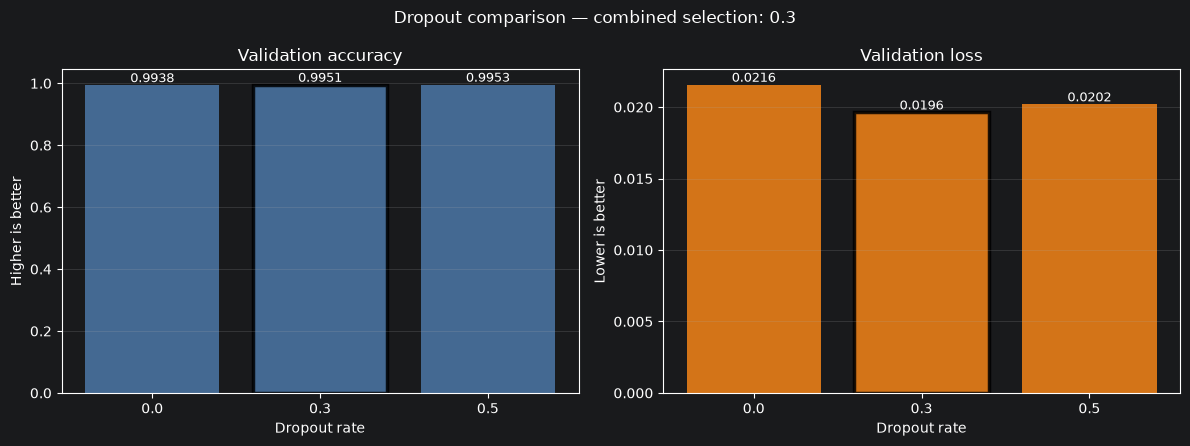

In [5]:
dropout_rates = [0.0, 0.3, 0.5]
dropout_results = {}
for rate in dropout_rates:
    print(f"\nDropout rate: {rate}")
    dropout_results[rate] = train_candidate(
        X_fit, y_fit, X_val, y_val,
        learning_rate=best_learning_rate, dropout_rate=rate, batch_size=128,
    )
best_dropout_rate = select_by_accuracy_and_loss(dropout_results)
plot_comparison(dropout_results, "Dropout comparison", "Dropout rate", best_dropout_rate)


## Compare batch sizes

The selected learning rate and dropout rate are held fixed. In the recorded comparison, validation accuracy was **99.4648%** for batch size 64, **99.4758%** for 128, and **99.4896%** for 256. The full spread is only about **0.025 percentage points**, so all three are within the 0.05-point tie range. Batch size **128** had the lowest validation loss (**0.01977**, versus 0.02201 for 64 and 0.02000 for 256), so the combined rule selects 128.



Batch size: 64
Epoch 1/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 26s 8ms/step - accuracy: 0.9723 - loss: 0.0931 - val_accuracy: 0.9903 - val_loss: 0.0330
Epoch 2/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9896 - loss: 0.0363 - val_accuracy: 0.9933 - val_loss: 0.0237
Epoch 3/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9921 - loss: 0.0266 - val_accuracy: 0.9934 - val_loss: 0.0244
Epoch 4/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9937 - loss: 0.0219 - val_accuracy: 0.9942 - val_loss: 0.0213
Epoch 5/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9948 - loss: 0.0178 - val_accuracy: 0.9943 - val_loss: 0.0230
Epoch 6/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9956 - loss: 0.0149 - val_accuracy: 0.9950 - val_loss: 0.0212
Epoch 7/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 25s 8ms/step - accuracy: 0.9961 - loss: 0.0132 - val_accuracy: 0.9947 - val_loss: 0.0229
Epoch 8/15
3184/3184 ━━━━━━━━━━━━━━━━━━━━ 27s 9ms/step - accuracy: 

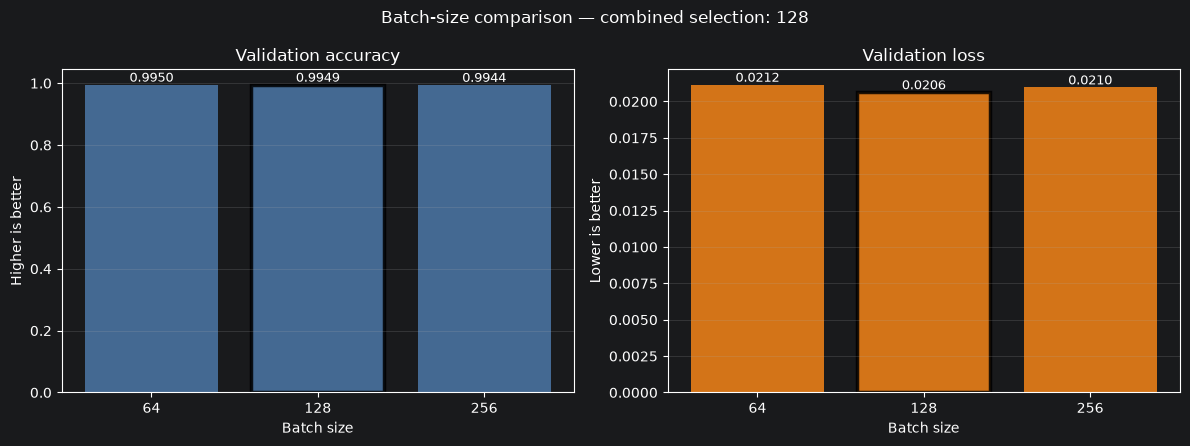

In [6]:
batch_sizes = [64, 128, 256]
batch_results = {}
for size in batch_sizes:
    print(f"\nBatch size: {size}")
    batch_results[size] = train_candidate(
        X_fit, y_fit, X_val, y_val,
        learning_rate=best_learning_rate,
        dropout_rate=best_dropout_rate,
        batch_size=size,
    )
best_batch_size = select_by_accuracy_and_loss(batch_results)
plot_comparison(batch_results, "Batch-size comparison", "Batch size", best_batch_size)


## Selected settings

This summary prints the settings chosen by the combined validation rule before the final run. Accuracy differences smaller than 0.05 percentage points are treated as a practical tie, and the lower validation loss breaks the tie.


In [7]:
print("Selected hyperparameters")
print("------------------------")
print(f"Learning rate : {best_learning_rate}")
print(f"Dropout rate  : {best_dropout_rate}")
print(f"Batch size    : {best_batch_size}")


Selected hyperparameters
------------------------
Learning rate : 0.001
Dropout rate  : 0.3
Batch size    : 128


## Train the selected model and evaluate once

Train using the selected settings, with validation loss controlling early stopping. The test split is first used in the next cell and is evaluated once. Its score is a final report, not another tuning signal.


In [8]:
final_result = train_candidate(
    X_fit, y_fit, X_val, y_val,
    learning_rate=best_learning_rate,
    dropout_rate=best_dropout_rate,
    batch_size=best_batch_size,
)
final_model = final_result["model"]
final_history = final_result["history"]


Epoch 1/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.9692 - loss: 0.1046 - val_accuracy: 0.9914 - val_loss: 0.0289
Epoch 2/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9890 - loss: 0.0372 - val_accuracy: 0.9926 - val_loss: 0.0245
Epoch 3/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9917 - loss: 0.0281 - val_accuracy: 0.9931 - val_loss: 0.0244
Epoch 4/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9931 - loss: 0.0231 - val_accuracy: 0.9935 - val_loss: 0.0225
Epoch 5/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9944 - loss: 0.0194 - val_accuracy: 0.9943 - val_loss: 0.0207
Epoch 6/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9951 - loss: 0.0165 - val_accuracy: 0.9947 - val_loss: 0.0207
Epoch 7/15
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9958 - loss: 0.0142 - val_accuracy: 0.9940 - val_loss: 0.0226


### Final model learning curves

These curves show how the selected model learned from fit writers and how its performance changed on the unseen validation writers. A widening training/validation gap can indicate overfitting.


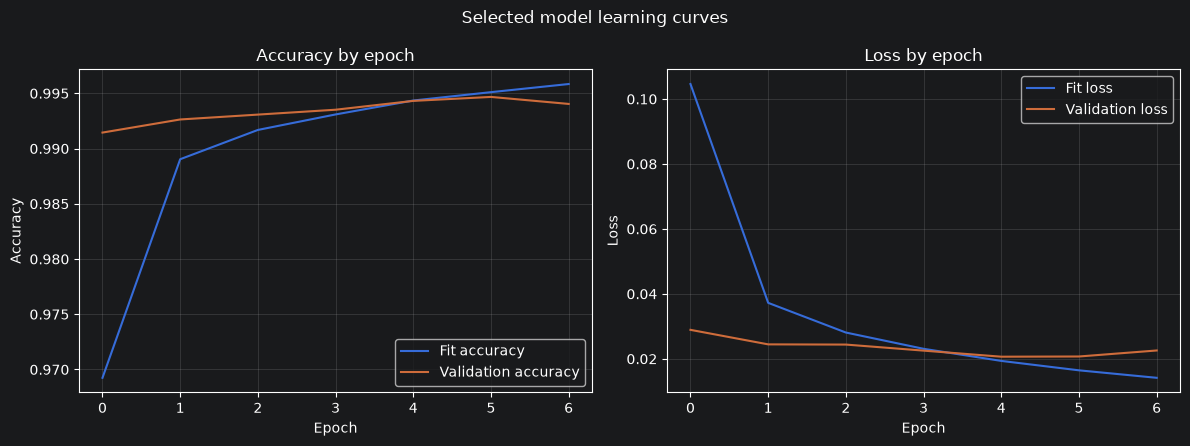

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(final_history.history["accuracy"], label="Fit accuracy")
axes[0].plot(final_history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy by epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(final_history.history["loss"], label="Fit loss")
axes[1].plot(final_history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss by epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.25)
fig.suptitle("Selected model learning curves")
fig.tight_layout()
plt.show()


In [10]:
test_loss, test_accuracy = final_model.evaluate(X_test, y_test, verbose=1)
print(f"Final test accuracy: {test_accuracy:.4f}")
print(f"Final test loss: {test_loss:.4f}")


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9947 - loss: 0.0188
Final test accuracy: 0.9947
Final test loss: 0.0188


## Save the model and experiment summary

The model and summary use new filenames so the previous tuned model and experiment outputs stay available. The JSON stores validation results for each candidate, which makes the plots reproducible without relying on notebook outputs alone.


In [11]:
import json

model_path = "../models/cnn_writer_independent.keras"
results_path = "../models/writer_independent_results.json"
final_model.save(model_path)

summary = {
    "validation_protocol": "GroupShuffleSplit by writer from original training split",
    "random_state": 42,
    "validation_fraction": 0.15,
    "fit_writers": len(fit_writers),
    "validation_writers": len(val_writers),
    "selection_rule": "lowest validation loss among configurations within 0.0005 accuracy of the best",
    "accuracy_tolerance": 0.0005,
    "learning_rate_candidates": candidate_summary(lr_results),
    "dropout_candidates": candidate_summary(dropout_results),
    "batch_size_candidates": candidate_summary(batch_results),
    "selected_learning_rate": float(best_learning_rate),
    "selected_dropout_rate": float(best_dropout_rate),
    "selected_batch_size": int(best_batch_size),
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "test_evaluations": 1,
}
with open(results_path, "w") as f:
    json.dump(summary, f, indent=2)
    f.write("\n")
print("Saved model:", model_path)
print("Saved results:", results_path)


Saved model: ../models/cnn_writer_independent.keras
Saved results: ../models/writer_independent_results.json


## Results and interpretation

The saved search selected learning rate **0.001**, dropout **0.3**, and batch size **128**. It first treats candidates within 0.05 percentage points of the best validation accuracy as tied, then selects the lowest validation loss. The final model reached **99.47% test accuracy** with **0.01885 test loss**. The saved model and JSON summary reflect these settings.

For batch size, 64 had the highest validation accuracy (**99.5007%**), while 128 scored **99.4896%** and had lower validation loss (**0.02063** versus **0.02115**). Those accuracy values are within the stated tie range, so the lower-loss setting, 128, was selected.

The validation split held out 537 writers with no overlap with the 3,042 fit writers. The supplied test split shares writer IDs with the original training split. Also, earlier exploratory notebooks reused the test split for comparisons, so treat this score as a project result rather than a never-before-seen benchmark.
